# Validasi & Pengujian Lengkap — MNB vs Logistic Regression pada IMDb 50K (TF-IDF)

**Judul:** *Comparative Analysis of Multinomial Naive Bayes and Logistic Regression for IMDb Movie Review Sentiment Classification Using TF-IDF*

**Acuan:** Ulya et al. (2025), *Reliable and Efficient Sentiment Analysis on IMDb with Logistic Regression*, CAUCHY 10(2), 821–834.

## Rumusan masalah

| RQ | Pertanyaan |
|---|---|
| **RQ1** | Seberapa besar perbedaan accuracy, precision, recall, F1-score, dan ROC-AUC antara MNB dan LR pada klasifikasi sentimen ulasan IMDb dengan fitur TF-IDF, dan apakah perbedaannya signifikan secara statistik? |
| **RQ2** | Bagaimana pola kesalahan (FP dan FN) kedua model, dan pada jenis ulasan apa (pendek/panjang, mengandung negasi) masing-masing model paling sering salah? |
| **RQ3** | Bagaimana konfigurasi TF-IDF (unigram vs unigram+bigram) dan tingkat preprocessing (minimal vs lanjutan, negasi dipertahankan) memengaruhi performa masing-masing model? |
| **RQ4** | Seberapa sensitif performa MNB (α) dan LR (C) terhadap hyperparameter, dan seberapa stabil kedua model pada pembagian data yang berbeda (Repeated Stratified K-Fold)? |
| **RQ5** | Bagaimana trade-off antara kualitas prediksi dan biaya komputasi (waktu training, prediksi, throughput), dan apakah selisih akurasi sebanding dengan selisih waktunya? |

## Peta notebook

| Bagian | Isi |
|---|---|
| 1–2 | Setup, konfigurasi, upload dataset |
| 3 | Validasi kualitas data |
| 4 | Preprocessing minimal vs lanjutan (negasi dipertahankan) |
| 5 | Split 70:30 + uji kebocoran (leakage) |
| 6 | Sanity check: dummy baseline & label-shuffle |
| 7 | Tuning hyperparameter (prasyarat model final; dianalisis di RQ4) |
| 8–9 | **RQ1** Metrik test set, ROC/PR/kalibrasi, McNemar, bootstrap CI |
| 10 | **RQ2** Komposisi FP/FN, error vs panjang & negasi, fitur, contoh error |
| 11 | **RQ3** Preprocessing (CV + test) dan n-gram TF-IDF |
| 12 | **RQ4** Sensitivitas hyperparameter + stabilitas Repeated Stratified CV |
| 13 | **RQ5** Waktu, throughput, dan trade-off kualitas vs biaya |
| 14 | Ringkasan otomatis per RQ & ekspor ZIP |

> Prinsip: **test set hanya dipakai untuk evaluasi akhir**. Semua pemilihan (hyperparameter, preprocessing, n-gram) dilakukan lewat CV pada data latih.

## 1. Instalasi & import

In [ ]:
!pip -q install nltk

In [ ]:
import os, re, io, html, time, json, glob, zipfile, platform, datetime, warnings
from functools import lru_cache

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn, scipy, nltk
from scipy.stats import binomtest, wilcoxon, t as t_dist
from IPython.display import display

from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.base import clone
from sklearn.dummy import DummyClassifier
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.pipeline import Pipeline
from sklearn.calibration import calibration_curve
from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold,
    RepeatedStratifiedKFold, cross_validate
)
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    average_precision_score, brier_score_loss, confusion_matrix,
    classification_report, roc_curve, precision_recall_curve
)

try:
    from google.colab import files
    IN_COLAB = True
except ImportError:
    files, IN_COLAB = None, False

warnings.filterwarnings("ignore")
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

for res in ["stopwords", "wordnet", "omw-1.4"]:
    nltk.download(res, quiet=True)

# ======================= KONFIGURASI =======================
SEED            = 42
TEST_SIZE       = 0.30
MAX_FEATURES    = 50000
CV_SPLITS       = 5          # CV untuk tuning/ablation (data latih)
RQ4_REPEATS     = 3          # Repeated Stratified 5-fold => 15 skor per model
N_BOOT          = 2000       # bootstrap test set
TIMING_REPEATS  = 5          # pengulangan pengukuran waktu RQ4
MAIN_TEXT       = "text_advanced"   # pipeline utama (sesuai protokol jurnal acuan)
TOKEN_PATTERN   = r"(?u)\b\w[\w']*\b"   # menjaga "don't", "isn't" sebagai satu token
# ===========================================================

FIG_FILES = []
def savefig(name):
    plt.tight_layout()
    plt.savefig(name, dpi=200, bbox_inches="tight")
    FIG_FILES.append(name)
    plt.show()

print("Python      :", platform.python_version())
print("pandas      :", pd.__version__)
print("numpy       :", np.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy       :", scipy.__version__)
print("nltk        :", nltk.__version__)
print("Mulai (UTC) :", datetime.datetime.now(datetime.timezone.utc).isoformat())

Python      : 3.13.16
pandas      : 2.2.3
numpy       : 2.1.3
scikit-learn: 1.6.1
scipy       : 1.16.3
nltk        : 3.9.1
Mulai (UTC) : 2026-10-27T03:56:38.779135+00:00


## 2. Upload dataset (`IMDB Dataset.csv` atau ZIP yang berisi CSV)

In [ ]:
if IN_COLAB:
    uploaded = files.upload()
else:
    uploaded = {}
    for p in glob.glob("*.csv") + glob.glob("*.zip"):
        with open(p, "rb") as fh:
            uploaded[p] = fh.read()

csv_candidates = []
for name, content in uploaded.items():
    if name.lower().endswith(".csv"):
        csv_candidates.append((name, content))
    elif name.lower().endswith(".zip"):
        with zipfile.ZipFile(io.BytesIO(content)) as z:
            for m in z.namelist():
                if m.lower().endswith(".csv") and not m.startswith("__MACOSX/"):
                    csv_candidates.append((m, z.read(m)))
if not csv_candidates:
    raise ValueError("Tidak ada CSV. Upload IMDB Dataset.csv atau ZIP berisi CSV.")

df, chosen_file = None, None
for name, content in csv_candidates:
    head = pd.read_csv(io.BytesIO(content), nrows=5)
    head.columns = head.columns.astype(str).str.strip().str.lower()
    if {"review", "sentiment"}.issubset(head.columns):
        df = pd.read_csv(io.BytesIO(content)); chosen_file = name; break
if df is None:
    raise ValueError("Tidak ada CSV dengan kolom 'review' dan 'sentiment'.")

df.columns = df.columns.astype(str).str.strip().str.lower()
print("File terpilih:", chosen_file, "| ukuran:", df.shape)
display(df.head(3))

Saving IMDb 50k Dataset.zip to IMDb 50k Dataset.zip
File terpilih: IMDB Dataset.csv | ukuran: (50000, 2)


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive


## 3. Validasi kualitas data

,Check,Value,Status
0,Baris pada CSV,50000.0,INFO
1,Review kosong (raw),0.0,PASS
2,Sentiment kosong (raw),0.0,PASS
3,Label tidak valid,0.0,PASS
4,Duplikat persis dibuang,418.0,INFO
5,Review identik berlabel konflik,0.0,PASS
6,Baris setelah deduplikasi,49582.0,INFO
7,Duplikat tersisa,0.0,PASS
8,Selisih kelas (|pos-neg|),186.0,INFO
9,Review mengandung tag HTML,28968.0,INFO


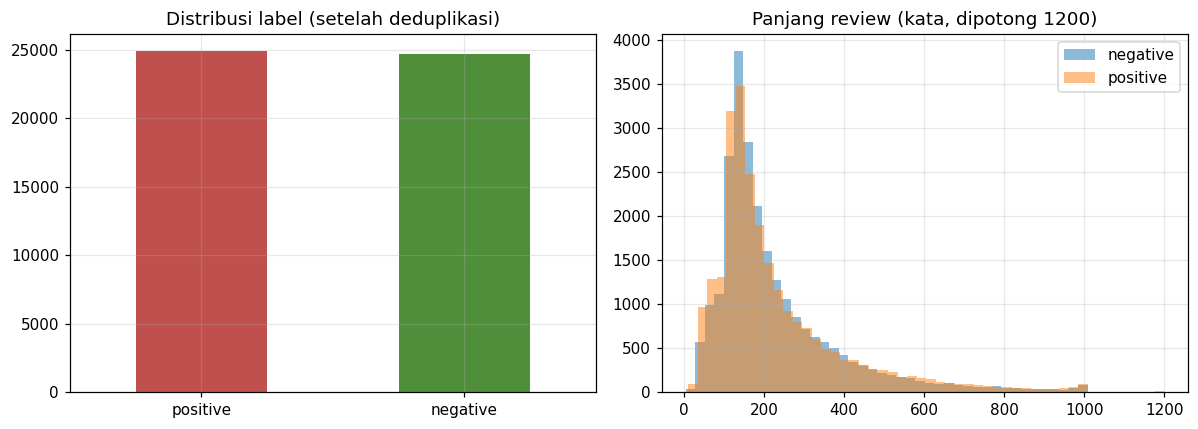

In [ ]:
raw_rows = len(df)
raw_missing_review = int(df["review"].isna().sum())
raw_missing_sent   = int(df["sentiment"].isna().sum())

data = df[["review", "sentiment"]].copy()
data["sentiment"] = data["sentiment"].astype("string").str.lower().str.strip()
invalid_labels = sorted(set(data["sentiment"].dropna().astype(str)) - {"positive", "negative"})

data = data.dropna(subset=["review", "sentiment"])
data = data[data["sentiment"].isin(["positive", "negative"])].copy()
data["review"] = data["review"].astype(str)

rows_before = len(data)
n_dup = int(data["review"].duplicated(keep="first").sum())
n_conflict = int(data.groupby("review")["sentiment"].nunique().gt(1).sum())

# Hapus duplikat persis SEBELUM split agar tidak ada review sama di train & test
data = data.drop_duplicates(subset="review", keep="first").reset_index(drop=True)
data["label"] = data["sentiment"].map({"negative": 0, "positive": 1}).astype(int)

data["n_words_raw"] = data["review"].str.split().str.len()
has_html = int(data["review"].str.contains(r"<[^>]+>", regex=True).sum())

def status(ok, warn=False): return "PASS" if ok else ("WARNING" if warn else "FAIL")

validation_report = pd.DataFrame([
    {"Check": "Baris pada CSV", "Value": raw_rows, "Status": "INFO"},
    {"Check": "Review kosong (raw)", "Value": raw_missing_review, "Status": status(raw_missing_review == 0, True)},
    {"Check": "Sentiment kosong (raw)", "Value": raw_missing_sent, "Status": status(raw_missing_sent == 0, True)},
    {"Check": "Label tidak valid", "Value": len(invalid_labels), "Status": status(len(invalid_labels) == 0, True)},
    {"Check": "Duplikat persis dibuang", "Value": n_dup, "Status": "INFO"},
    {"Check": "Review identik berlabel konflik", "Value": n_conflict, "Status": status(n_conflict == 0, True)},
    {"Check": "Baris setelah deduplikasi", "Value": len(data), "Status": "INFO"},
    {"Check": "Duplikat tersisa", "Value": int(data["review"].duplicated().sum()), "Status": status(data["review"].duplicated().sum() == 0)},
    {"Check": "Selisih kelas (|pos-neg|)", "Value": int(abs((data.label == 1).sum() - (data.label == 0).sum())), "Status": "INFO"},
    {"Check": "Review mengandung tag HTML", "Value": has_html, "Status": "INFO"},
    {"Check": "Median panjang review (kata)", "Value": float(data["n_words_raw"].median()), "Status": "INFO"},
    {"Check": "Review < 5 kata", "Value": int((data["n_words_raw"] < 5).sum()), "Status": status((data["n_words_raw"] < 5).sum() == 0, True)},
])
display(validation_report)
assert len(data) > 0 and data["label"].nunique() == 2, "Dataset kosong / satu kelas"

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
data["sentiment"].value_counts().plot(kind="bar", ax=ax[0], color=["#c0504d", "#4f8f3a"])
ax[0].set_title("Distribusi label (setelah deduplikasi)"); ax[0].set_xlabel(""); ax[0].tick_params(axis="x", rotation=0)
for lab, g in data.groupby("sentiment"):
    ax[1].hist(g["n_words_raw"].clip(upper=1200), bins=50, alpha=0.5, label=lab)
ax[1].set_title("Panjang review (kata, dipotong 1200)"); ax[1].legend()
savefig("dataset_distribusi.png")

## 4. Preprocessing minimal vs lanjutan

Perbaikan dari versi sebelumnya: **semua bentuk negasi NLTK** (*don't, isn't, wasn't, …*) dipertahankan, bukan hanya `no/nor/not`. Token memakai pola yang menjaga apostrof, sehingga `don't` tidak terpecah menjadi `don` + `t`.

In [ ]:
BASE_STOP = set(stopwords.words("english"))
NEGATIONS = {w for w in BASE_STOP if w.endswith("n't")} | {"no", "nor", "not"}
STOP_WORDS = BASE_STOP - NEGATIONS
print(f"Stopword dasar: {len(BASE_STOP)} | negasi dipertahankan: {len(NEGATIONS)} | stopword dipakai: {len(STOP_WORDS)}")
print("Contoh negasi yang dipertahankan:", sorted(NEGATIONS)[:12], "...")

_LEM = WordNetLemmatizer()
@lru_cache(maxsize=None)
def lemma(w): return _LEM.lemmatize(w)

TAG_RE = re.compile(r"<[^>]+>")
URL_RE = re.compile(r"https?://\S+|www\.\S+")
NON_ALPHA_RE = re.compile(r"[^a-z'\s]")

def minimal_preprocessing(text):
    text = html.unescape(str(text))
    text = TAG_RE.sub(" ", text)
    text = text.replace("\u2019", "'").lower()
    return re.sub(r"\s+", " ", text).strip()

def advanced_preprocessing(text):
    text = URL_RE.sub(" ", minimal_preprocessing(text))
    text = NON_ALPHA_RE.sub(" ", text)
    tokens = (t.strip("'") for t in text.split())
    return " ".join(lemma(t) for t in tokens if len(t) > 1 and t not in STOP_WORDS)

t0 = time.perf_counter()
data["text_minimal"]  = data["review"].map(minimal_preprocessing)
data["text_advanced"] = data["review"].map(advanced_preprocessing)
print(f"Preprocessing selesai dalam {time.perf_counter() - t0:.1f} s")

empty_adv = int((data["text_advanced"].str.len() == 0).sum())
print("Review kosong setelah preprocessing lanjutan:", empty_adv)
assert data["text_minimal"].str.contains("<br").sum() == 0, "Tag HTML masih tersisa"
display(data[["review", "text_minimal", "text_advanced"]].head(2).style.set_properties(**{"text-align": "left"}))

Stopword dasar: 198 | negasi dipertahankan: 21 | stopword dipakai: 177
Contoh negasi yang dipertahankan: ["aren't", "couldn't", "didn't", "doesn't", "don't", "hadn't", "hasn't", "haven't", "isn't", "mightn't", "mustn't", "needn't"] ...
Preprocessing selesai dalam 21.1 s
Review kosong setelah preprocessing lanjutan: 0


,review,text_minimal,text_advanced
0,"One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.I would say the main appeal of the show is due to the fact that it goes where other shows wouldn't dare. Forget pretty pictures painted for mainstream audiences, forget charm, forget romance...OZ doesn't mess around. The first episode I ever saw struck me as so nasty it was surreal, I couldn't say I was ready for it, but as I watched more, I developed a taste for Oz, and got accustomed to the high levels of graphic violence. Not just violence, but injustice (crooked guards who'll be sold out for a nickel, inmates who'll kill on order and get away with it, well mannered, middle class inmates being turned into prison bitches due to their lack of street skills or prison experience) Watching Oz, you may become comfortable with what is uncomfortable viewing....thats if you can get in touch with your darker side.","one of the other reviewers has mentioned that after watching just 1 oz episode you'll be hooked. they are right, as this is exactly what happened with me. the first thing that struck me about oz was its brutality and unflinching scenes of violence, which set in right from the word go. trust me, this is not a show for the faint hearted or timid. this show pulls no punches with regards to drugs, sex or violence. its is hardcore, in the classic use of the word. it is called oz as that is the nickname given to the oswald maximum security state penitentary. it focuses mainly on emerald city, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. em city is home to many..aryans, muslims, gangstas, latinos, christians, italians, irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away. i would say the main appeal of the show is due to the fact that it goes where other shows wouldn't dare. forget pretty pictures painted for mainstream audiences, forget charm, forget romance...oz doesn't mess around. the first episode i ever saw struck me as so nasty it was surreal, i couldn't say i was ready for it, but as i watched more, i developed a taste for oz, and got accustomed to the high levels of graphic violence. not just violence, but injustice (crooked guards who'll be sold out for a nickel, inmates who'll kill on order and get away with it, well mannered, middle class inmates being turned into prison bitches due to their lack of street skills or prison experience) watching oz, you may become comfortable with what is uncomfortable viewing....thats if you can get in touch with your darker side.",one reviewer mentioned watching oz episode hooked right exactly happened first thing struck oz brutality unflinching scene violence set right word go trust not show faint hearted timid show pull no punch regard drug sex violence hardcore classic use word called oz nickname given oswald maximum security state penitentary focus mainly emerald city experimental section prison cell glass front face inwards privacy not high agenda em city home many aryan muslim gangsta latino christian italian irish scuf

## 5. Split 70:30 stratified + uji kebocoran (leakage)

In [ ]:
train_idx, test_idx = train_test_split(
    data.index, test_size=TEST_SIZE, stratify=data["label"], random_state=SEED
)
train, test = data.loc[train_idx].copy(), data.loc[test_idx].copy()
y_train, y_test = train["label"].to_numpy(), test["label"].to_numpy()
X_train, X_test = train[MAIN_TEXT], test[MAIN_TEXT]

# --- uji kebocoran ---
overlap_raw = len(set(train["review"]) & set(test["review"]))
overlap_adv = len(set(train["text_advanced"]) & set(test["text_advanced"]))
assert len(train) + len(test) == len(data)
assert overlap_raw == 0, "LEAKAGE: review identik di train dan test"
split_report = pd.DataFrame([
    {"Split": "Train", "Rows": len(train), "Negative": int((y_train == 0).sum()), "Positive": int((y_train == 1).sum())},
    {"Split": "Test",  "Rows": len(test),  "Negative": int((y_test == 0).sum()),  "Positive": int((y_test == 1).sum())},
])
display(split_report)
print(f"PASS  review identik train∩test (raw)        : {overlap_raw}")
print(f"INFO  teks identik setelah preprocessing     : {overlap_adv}  (near-duplicate; catat sebagai keterbatasan bila > 0)")
print(f"PASS  proporsi positif train={y_train.mean():.4f}  test={y_test.mean():.4f}")

# --- helper pipeline & metrik ---
def make_pipe(model, ngram=(1, 1)):
    return Pipeline([
        ("tfidf", TfidfVectorizer(lowercase=False, token_pattern=TOKEN_PATTERN,
                                  max_features=MAX_FEATURES, ngram_range=ngram, sublinear_tf=True)),
        ("model", model),
    ])

def metric_row(name, y, pred, proba):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    return {
        "Model": name, "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
        "Accuracy": accuracy_score(y, pred), "Precision": precision_score(y, pred, zero_division=0),
        "Recall": recall_score(y, pred, zero_division=0), "F1-score": f1_score(y, pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y, proba), "PR-AUC": average_precision_score(y, proba),
        "Brier": brier_score_loss(y, proba),
    }

def fast_f1(y, p):
    tp = np.sum((y == 1) & (p == 1)); fp = np.sum((y == 0) & (p == 1)); fn = np.sum((y == 1) & (p == 0))
    d = 2 * tp + fp + fn
    return 2 * tp / d if d else 0.0

# --- uji: vocabulary TF-IDF hanya dari data latih ---
_probe = make_pipe(MultinomialNB()).fit(X_train, y_train)
vocab = set(_probe.named_steps["tfidf"].vocabulary_)
train_tokens = set(" ".join(X_train).split())
test_only = {w for w in " ".join(X_test).split() if w not in train_tokens}
leaked = [w for w in test_only if w in vocab]
assert not leaked, f"LEAKAGE: vocabulary memuat kata khusus test: {leaked[:5]}"
print(f"PASS  vocabulary TF-IDF bebas kata khusus-test ({len(test_only)} kata unik hanya di test, 0 masuk vocabulary)")

,Split,Rows,Negative,Positive
0,Train,34707,17288,17419
1,Test,14875,7410,7465


PASS  review identik train∩test (raw)        : 0
INFO  teks identik setelah preprocessing     : 3  (near-duplicate; catat sebagai keterbatasan bila > 0)
PASS  proporsi positif train=0.5019  test=0.5018
PASS  vocabulary TF-IDF bebas kata khusus-test (14309 kata unik hanya di test, 0 masuk vocabulary)


## 6. Sanity check: dummy baseline & label-shuffle

In [ ]:
rng = np.random.default_rng(SEED)
dummy = make_pipe(DummyClassifier(strategy="most_frequent")).fit(X_train, y_train)
acc_dummy = accuracy_score(y_test, dummy.predict(X_test))

lr_shuf = make_pipe(LogisticRegression(max_iter=1000, random_state=SEED)).fit(X_train, rng.permutation(y_train))
acc_shuf = accuracy_score(y_test, lr_shuf.predict(X_test))
auc_shuf = roc_auc_score(y_test, lr_shuf.predict_proba(X_test)[:, 1])

sanity = pd.DataFrame([
    {"Check": "Dummy (kelas mayoritas) accuracy", "Value": acc_dummy, "Harapan": "≈ 0.50"},
    {"Check": "LR label diacak: accuracy", "Value": acc_shuf, "Harapan": "≈ 0.50 (dalam ±4 galat baku)"},
    {"Check": "LR label diacak: ROC-AUC", "Value": auc_shuf, "Harapan": "≈ 0.50 (dalam ±4 galat baku)"},
])
display(sanity.round(4))
tol = max(0.03, 4 * np.sqrt(0.25 / len(y_test)))    # ~4 galat baku tebakan acak
assert abs(acc_shuf - 0.5) < tol and abs(auc_shuf - 0.5) < tol, \
    "Model dengan label acak terlalu bagus -> curiga ada kebocoran!"
print("PASS: model dengan label acak ≈ tebakan. Tidak ada indikasi kebocoran label/teks.")

,Check,Value,Harapan
0,Dummy (kelas mayoritas) accuracy,0.5018,≈ 0.50
1,LR label diacak: accuracy,0.4943,≈ 0.50 (dalam ±4 galat baku)
2,LR label diacak: ROC-AUC,0.4922,≈ 0.50 (dalam ±4 galat baku)


PASS: model dengan label acak ≈ tebakan. Tidak ada indikasi kebocoran label/teks.


## 7. Tuning hyperparameter (prasyarat model final)

Grid search 5-fold CV (skor F1) **hanya pada data latih** untuk memilih α (MNB) dan C (LR). Model terbaik dipakai pada RQ1–RQ5; analisis sensitivitasnya dibahas pada **RQ4**.

In [ ]:
cv5 = StratifiedKFold(n_splits=CV_SPLITS, shuffle=True, random_state=SEED)

grid_mnb = GridSearchCV(make_pipe(MultinomialNB()), {"model__alpha": [0.1, 0.5, 1.0, 2.0]},
                        scoring="f1", cv=cv5, n_jobs=-1, refit=True, return_train_score=True)
grid_lr = GridSearchCV(make_pipe(LogisticRegression(max_iter=1000, random_state=SEED)),
                       {"model__C": [0.25, 0.5, 1, 2, 4]},
                       scoring="f1", cv=cv5, n_jobs=-1, refit=True, return_train_score=True)
grid_mnb.fit(X_train, y_train)
grid_lr.fit(X_train, y_train)

best_alpha = grid_mnb.best_params_["model__alpha"]
best_C = grid_lr.best_params_["model__C"]
print(f"Terbaik MNB: alpha={best_alpha} | CV F1={grid_mnb.best_score_:.4f}")
print(f"Terbaik LR : C={best_C} | CV F1={grid_lr.best_score_:.4f}")

Terbaik MNB: alpha=1.0 | CV F1=0.8623
Terbaik LR : C=2 | CV F1=0.8968


## 8. RQ1 — Performa komparatif

> **RQ1.** Seberapa besar perbedaan accuracy, precision, recall, F1-score, dan ROC-AUC antara Multinomial Naive Bayes dan Logistic Regression pada klasifikasi sentimen ulasan IMDb dengan fitur TF-IDF, dan apakah perbedaannya signifikan secara statistik?

Test set dipakai sekali untuk perbandingan final. Empat baris dilaporkan: **default** (α=1, C=1) dan **tuned** (hasil tuning). Perbandingan utama dan uji statistik memakai model *tuned*.

,Model,TN,FP,FN,TP,Accuracy,Precision,Recall,F1-score,ROC-AUC,PR-AUC,Brier
0,"MNB (default, alpha=1)",6499,911,1107,6358,0.8643,0.8747,0.8517,0.8630,0.9374,0.9351,0.1162
1,"MNB (tuned, alpha=1.0)",6499,911,1107,6358,0.8643,0.8747,0.8517,0.8630,0.9374,0.9351,0.1162
2,"LR (default, C=1)",6494,916,667,6798,0.8936,0.8813,0.9106,0.8957,0.9603,0.9594,0.0838
3,"LR (tuned, C=2)",6532,878,672,6793,0.8958,0.8855,0.9100,0.8976,0.9617,0.9608,0.0785



 MNB (tuned, alpha=1.0)
              precision    recall  f1-score   support

    Negative     0.8545    0.8771    0.8656      7410
    Positive     0.8747    0.8517    0.8630      7465

    accuracy                         0.8643     14875
   macro avg     0.8646    0.8644    0.8643     14875
weighted avg     0.8646    0.8643    0.8643     14875


 LR (tuned, C=2)
              precision    recall  f1-score   support

    Negative     0.9067    0.8815    0.8939      7410
    Positive     0.8855    0.9100    0.8976      7465

    accuracy                         0.8958     14875
   macro avg     0.8961    0.8957    0.8958     14875
weighted avg     0.8961    0.8958    0.8958     14875



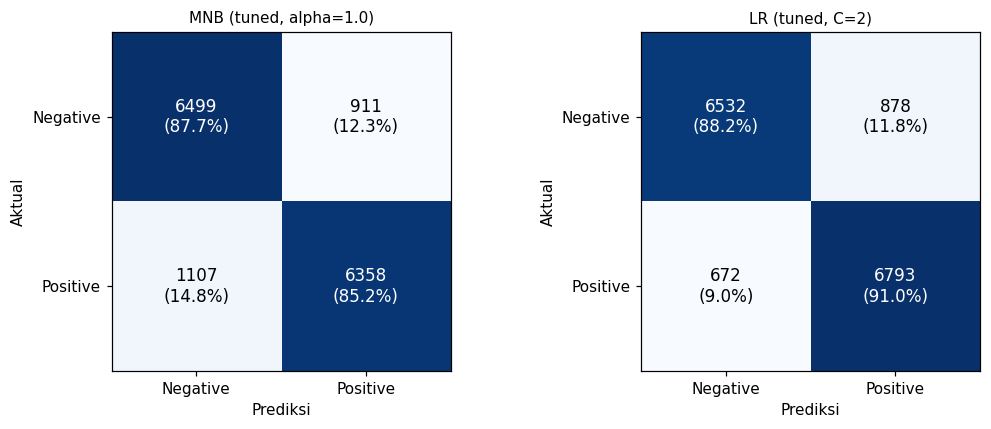

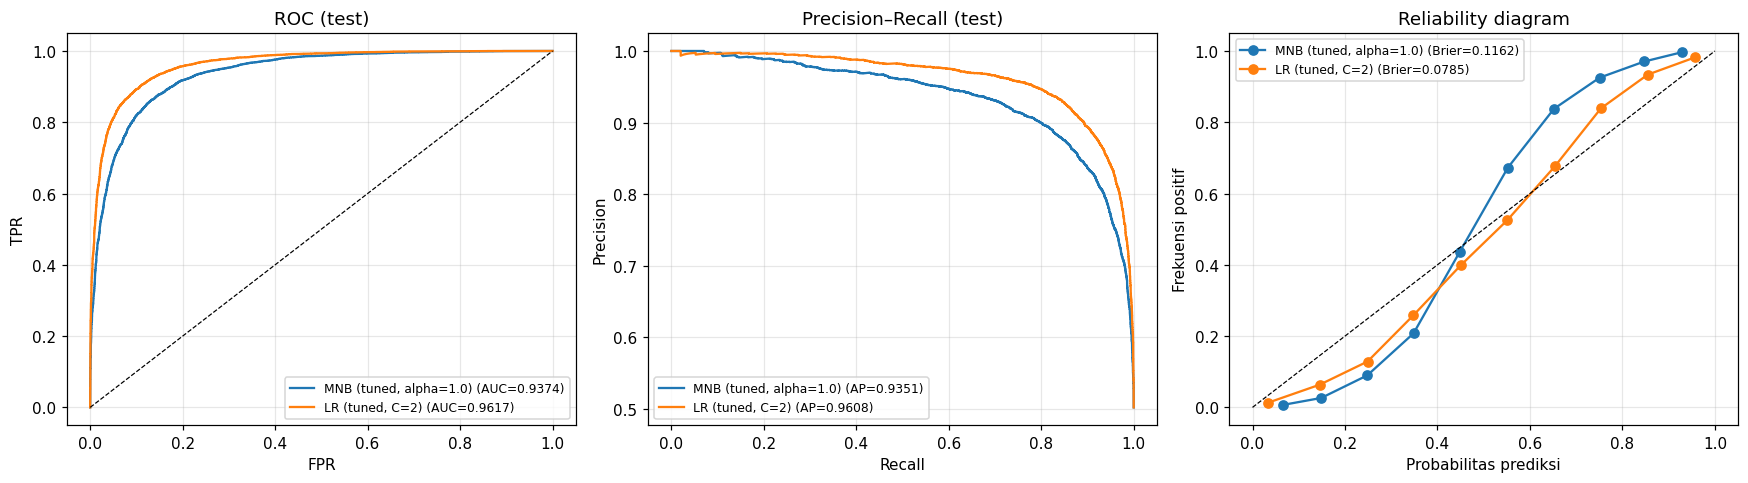

In [ ]:
mnb_default = make_pipe(MultinomialNB(alpha=1.0)).fit(X_train, y_train)
lr_default  = make_pipe(LogisticRegression(C=1.0, max_iter=1000, random_state=SEED)).fit(X_train, y_train)
mnb_tuned, lr_tuned = grid_mnb.best_estimator_, grid_lr.best_estimator_   # sudah refit pada seluruh data latih

models_final = {
    "MNB (default, alpha=1)": mnb_default,
    f"MNB (tuned, alpha={best_alpha})": mnb_tuned,
    "LR (default, C=1)": lr_default,
    f"LR (tuned, C={best_C})": lr_tuned,
}
preds, probas, rows = {}, {}, []
for nm, m in models_final.items():
    preds[nm] = m.predict(X_test); probas[nm] = m.predict_proba(X_test)[:, 1]
    rows.append(metric_row(nm, y_test, preds[nm], probas[nm]))
rq1_df = pd.DataFrame(rows)
display(rq1_df.round(4))

NM_MNB, NM_LR = f"MNB (tuned, alpha={best_alpha})", f"LR (tuned, C={best_C})"
for nm in [NM_MNB, NM_LR]:
    print("\n", nm)
    print(classification_report(y_test, preds[nm], target_names=["Negative", "Positive"], digits=4))

# Confusion matrix (dengan persentase baris)
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, nm in zip(ax, [NM_MNB, NM_LR]):
    cm = confusion_matrix(y_test, preds[nm], labels=[0, 1])
    a.imshow(cm, cmap="Blues"); a.grid(False)
    for i in range(2):
        for j in range(2):
            a.text(j, i, f"{cm[i, j]}\n({cm[i, j] / cm[i].sum():.1%})", ha="center", va="center",
                   color="white" if cm[i, j] > cm.max() / 2 else "black", fontsize=11)
    a.set_xticks([0, 1], ["Negative", "Positive"]); a.set_yticks([0, 1], ["Negative", "Positive"])
    a.set_xlabel("Prediksi"); a.set_ylabel("Aktual"); a.set_title(nm, fontsize=10)
savefig("RQ1_confusion_matrix.png")

# ROC, PR, Kalibrasi
fig, ax = plt.subplots(1, 3, figsize=(16, 4.5))
for nm in [NM_MNB, NM_LR]:
    fpr, tpr, _ = roc_curve(y_test, probas[nm]); ax[0].plot(fpr, tpr, label=f"{nm} (AUC={roc_auc_score(y_test, probas[nm]):.4f})")
    pr, rc, _ = precision_recall_curve(y_test, probas[nm]); ax[1].plot(rc, pr, label=f"{nm} (AP={average_precision_score(y_test, probas[nm]):.4f})")
    fy, fx = calibration_curve(y_test, probas[nm], n_bins=10, strategy="uniform"); ax[2].plot(fx, fy, marker="o", label=f"{nm} (Brier={brier_score_loss(y_test, probas[nm]):.4f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=0.8); ax[0].set(title="ROC (test)", xlabel="FPR", ylabel="TPR")
ax[1].set(title="Precision–Recall (test)", xlabel="Recall", ylabel="Precision")
ax[2].plot([0, 1], [0, 1], "k--", lw=0.8); ax[2].set(title="Reliability diagram", xlabel="Probabilitas prediksi", ylabel="Frekuensi positif")
for a in ax: a.legend(fontsize=8)
savefig("RQ1_roc_pr_kalibrasi.png")

## 9. RQ1 (lanjutan) — Uji signifikansi statistik pada test set

* **McNemar exact** — apakah proporsi kesalahan kedua model berbeda pada kasus yang sama.
* **Bootstrap berpasangan** — CI 95% untuk selisih Accuracy dan F1 (LR − MNB), serta CI masing-masing model.

In [ ]:
p_m, p_l = preds[NM_MNB], preds[NM_LR]
ok_m, ok_l = p_m == y_test, p_l == y_test
b = int(np.sum(~ok_m & ok_l)); c = int(np.sum(ok_m & ~ok_l))     # b: hanya LR benar, c: hanya MNB benar
mcnemar_p = 1.0 if b + c == 0 else float(binomtest(min(b, c), b + c, 0.5).pvalue)

rng = np.random.default_rng(SEED + 100)
n = len(y_test)
acc_d, f1_d, f1_m, f1_l = (np.empty(N_BOOT) for _ in range(4))
for i in range(N_BOOT):
    ix = rng.integers(0, n, n)
    yt, pm, pl = y_test[ix], p_m[ix], p_l[ix]
    acc_d[i] = np.mean(pl == yt) - np.mean(pm == yt)
    f1_m[i], f1_l[i] = fast_f1(yt, pm), fast_f1(yt, pl)
    f1_d[i] = f1_l[i] - f1_m[i]
ci = lambda a: tuple(np.percentile(a, [2.5, 97.5]))

rq1_stats = pd.DataFrame([
    {"Uji": "McNemar exact (hanya LR benar b vs hanya MNB benar c)", "Estimasi": b - c, "CI95 bawah": np.nan, "CI95 atas": np.nan, "p-value": mcnemar_p, "Catatan": f"b={b}, c={c}"},
    {"Uji": "Bootstrap Δ Accuracy (LR − MNB)", "Estimasi": np.mean(p_l == y_test) - np.mean(p_m == y_test), "CI95 bawah": ci(acc_d)[0], "CI95 atas": ci(acc_d)[1], "p-value": np.nan, "Catatan": "CI tidak memuat 0 → beda"},
    {"Uji": "Bootstrap Δ F1 (LR − MNB)", "Estimasi": fast_f1(y_test, p_l) - fast_f1(y_test, p_m), "CI95 bawah": ci(f1_d)[0], "CI95 atas": ci(f1_d)[1], "p-value": np.nan, "Catatan": "CI tidak memuat 0 → beda"},
    {"Uji": "Bootstrap F1 MNB", "Estimasi": fast_f1(y_test, p_m), "CI95 bawah": ci(f1_m)[0], "CI95 atas": ci(f1_m)[1], "p-value": np.nan, "Catatan": ""},
    {"Uji": "Bootstrap F1 LR", "Estimasi": fast_f1(y_test, p_l), "CI95 bawah": ci(f1_l)[0], "CI95 atas": ci(f1_l)[1], "p-value": np.nan, "Catatan": ""},
])
display(rq1_stats.round(6))
print("Catatan: p-value McNemar yang sangat kecil pada n besar wajar; tafsirkan bersama ukuran efek (Δ F1) dan CI-nya.")

,Uji,Estimasi,CI95 bawah,CI95 atas,p-value,Catatan
0,McNemar exact (hanya LR benar b vs hanya MNB b...,468.000000,NaN,NaN,0.0,"b=1012, c=544"
1,Bootstrap Δ Accuracy (LR − MNB),0.031462,0.026351,0.036571,NaN,CI tidak memuat 0 → beda
2,Bootstrap Δ F1 (LR − MNB),0.034557,0.029404,0.039696,NaN,CI tidak memuat 0 → beda
3,Bootstrap F1 MNB,0.863038,0.857221,0.869003,NaN,
4,Bootstrap F1 LR,0.897595,0.892564,0.902773,NaN,


Catatan: p-value McNemar yang sangat kecil pada n besar wajar; tafsirkan bersama ukuran efek (Δ F1) dan CI-nya.


## 10. RQ2 — Pola kesalahan

> **RQ2.** Bagaimana pola kesalahan klasifikasi (false positive dan false negative) kedua model, dan pada jenis ulasan apa (misalnya ulasan pendek atau panjang, atau yang mengandung negasi) masing-masing model paling sering salah?

Dianalisis: (a) komposisi FP vs FN, (b) error menurut panjang review, (c) error menurut jumlah kata negasi, (d) fitur paling berpengaruh, (e) contoh salah klasifikasi paling yakin.

Dua model salah: 1006 | hanya MNB salah: 1012 | hanya LR salah: 544


,Model,FP (negatif diprediksi positif),FN (positif diprediksi negatif),Total error,FN / FP
0,"MNB (tuned, alpha=1.0)",911,1107,2018,1.215
1,"LR (tuned, C=2)",878,672,1550,0.765


,len_bin,n,Error MNB,Error LR
0,Q1 pendek,3803,0.1357,0.1018
1,Q2,3666,0.1394,0.1031
2,Q3,3701,0.1313,0.1086
3,Q4 panjang,3705,0.1363,0.1034


,neg_bin,n,Error MNB,Error LR
0,0,2386,0.1316,0.0993
1,1–2,5899,0.1356,0.1034
2,3–5,4442,0.1378,0.1069
3,>5,2148,0.1359,0.1061


Catatan: review yang panjang cenderung memuat lebih banyak negasi, jadi (b) dan (c) tidak sepenuhnya independen.


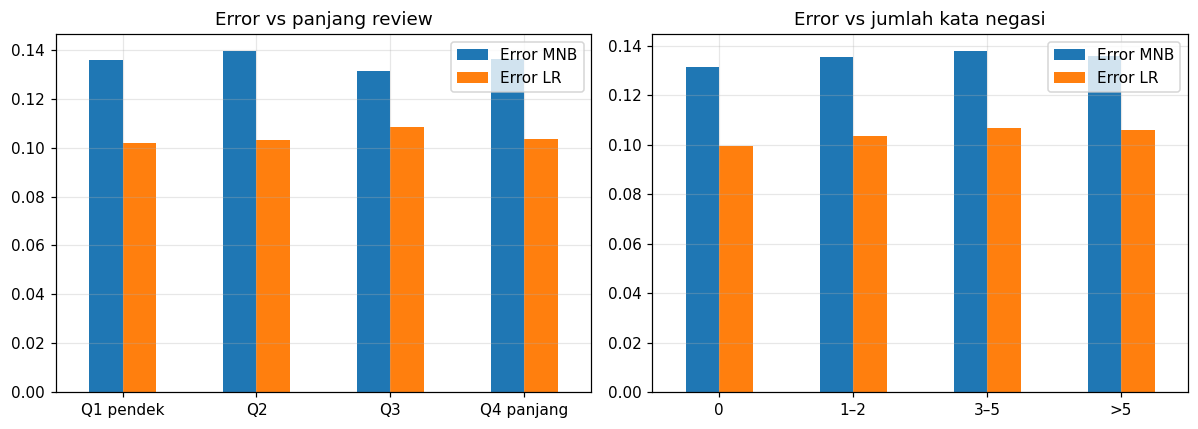

Top fitur Logistic Regression (koefisien)


,Negatif,Positif
0,worst,great
1,bad,excellent
2,awful,perfect
3,waste,best
4,boring,amazing
5,poor,wonderful
6,terrible,favorite
7,horrible,brilliant
8,disappointing,loved
9,fails,enjoyed


Top fitur MNB (log P(w|pos) − log P(w|neg))


,Negatif,Positif
0,waste,matthau
1,worst,flawless
2,stinker,unforgettable
3,awful,wonderfully
4,unfunny,excellently
5,mst,rory
6,redeeming,timeless
7,uwe,ponyo
8,boll,paulie
9,wasting,underrated


Token negasi yang masuk vocabulary: 20 (contoh: ["aren't", "couldn't", "didn't", "doesn't", "don't", "hadn't", "hasn't", "haven't"])


,label,pred_lr,conf,review
8592,1,0,0.997,"This movie has everything that makes a bad movie worth watching - sloppy editing, little to no continuity, insane dialog, bad (you might even say non-existent) acting, pointless story lines, shots that go on FAR too long...and it's perfect for MST3K-style riffing, not to mention the ""Corpse Eaters Drinking Game"": Scribble on forms...take a shot - S..."
23424,0,1,0.996,"this one of the best celebrity's reality shows a ever saw. we can see the concerts we can see the life of Britney, i love the five episodes. i was always being surprised by Britney and the subjects of the show i think that some people don't watch the show at all we can how a great person she his. she his really funny really gentle and she loves her..."
15877,0,1,0.992,This is definitely one of the best Kung fu movies in the history of Cinema. The screenplay is really well done (which is not often the case for this type of movies) and you can see that Chuck (in one of his first role)is a great actor. The final fight with the sherif deputy in the bullring is a masterpiece!...
43276,1,0,0.990,**SPOILERS AHEAD**<br /><br />It is really unfortunate that a movie so well produced turns out to be<br /><br />such a disappointment. I thought this was full of (silly) clichés and<br /><br />that it basically tried to hard. <br /><br />To the (American) guys out there: how many of you spend your<br /><br />time jumping on your girlfriend's bed an...
31999,1,0,0.989,"Actually I liked this movie very, very much. Not because of it`s plot, acting, jokes, no. I liked it, because it`s one of the worse movies ever created. It`s so lame, so bad, that it becomes terribly funny. Some jokes are actually cool, but the rest makes me pray for unemployment for the scriptwriter. ""Men in white"" are so dumb and stupid, that you..."
22355,1,0,0.989,"This is simply the funniest movie I've seen in a long time. The bad acting, bad script, bad scenery, bad costumes, bad camera work and bad special effects are so stupid that you find yourself reeling with laughter.<br /><br />So it's not gonna win an Oscar but if you've got beer and friends round then you can't go wrong...."
28756,0,1,0.986,"This has to be one of, if not THE greatest Mob/Crime films of all time. Every thing about this movie is great, the acting in this film is of true quality; Master P's acting skills make you actually believe he is Italian! The cinematography is excellent too, probably the best ever. This movie was great; and I have the brain capacity of an earth worm..."
27086,1,0,0.985,"I've read some terrible things about this film, so I was prepared for the worst. ""Confusing. Muddled. Horribly structured."" While there may be merit to some of these accusations, this film was nowhere near as horrific as your average DVD programmer. In fact, it actually had aspirations. It attempted something beyond the typical monster/slasher nons..."


In [ ]:
test = test.copy()
test["pred_mnb"], test["pred_lr"] = p_m, p_l
test["proba_lr"], test["proba_mnb"] = probas[NM_LR], probas[NM_MNB]
test["err_mnb"] = test.pred_mnb != test.label
test["err_lr"] = test.pred_lr != test.label
print("Dua model salah:", int((test.err_mnb & test.err_lr).sum()),
      "| hanya MNB salah:", int((test.err_mnb & ~test.err_lr).sum()),
      "| hanya LR salah:", int((~test.err_mnb & test.err_lr).sum()))

# (a) komposisi FP vs FN
rows = []
for nm in [NM_MNB, NM_LR]:
    r = rq1_df[rq1_df.Model == nm].iloc[0]
    rows.append({"Model": nm, "FP (negatif diprediksi positif)": r["FP"], "FN (positif diprediksi negatif)": r["FN"],
                 "Total error": r["FP"] + r["FN"], "FN / FP": r["FN"] / max(r["FP"], 1)})
rq2_komposisi = pd.DataFrame(rows); display(rq2_komposisi.round(3))

# (b) error vs panjang review (kuartil)
test["len_bin"] = pd.qcut(test["n_words_raw"], 4, labels=["Q1 pendek", "Q2", "Q3", "Q4 panjang"])
rq2_panjang = (test.groupby("len_bin", observed=True)
               .agg(n=("label", "size"), **{"Error MNB": ("err_mnb", "mean"), "Error LR": ("err_lr", "mean")}).reset_index())
display(rq2_panjang.round(4))

# (c) error vs jumlah kata negasi (catatan: berkorelasi dengan panjang review)
neg_count = test["text_minimal"].map(lambda s: sum(w in NEGATIONS for w in re.findall(r"[a-z']+", s)))
test["neg_bin"] = pd.cut(neg_count, [-1, 0, 2, 5, np.inf], labels=["0", "1–2", "3–5", ">5"])
rq2_negasi = (test.groupby("neg_bin", observed=True)
              .agg(n=("label", "size"), **{"Error MNB": ("err_mnb", "mean"), "Error LR": ("err_lr", "mean")}).reset_index())
display(rq2_negasi.round(4))
print("Catatan: review yang panjang cenderung memuat lebih banyak negasi, jadi (b) dan (c) tidak sepenuhnya independen.")

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
rq2_panjang.set_index("len_bin")[["Error MNB", "Error LR"]].plot(kind="bar", ax=ax[0], rot=0); ax[0].set_title("Error vs panjang review"); ax[0].set_xlabel("")
rq2_negasi.set_index("neg_bin")[["Error MNB", "Error LR"]].plot(kind="bar", ax=ax[1], rot=0); ax[1].set_title("Error vs jumlah kata negasi"); ax[1].set_xlabel("")
savefig("RQ2_error_panjang_negasi.png")

# (d) fitur paling berpengaruh
names = np.array(lr_tuned.named_steps["tfidf"].get_feature_names_out())
coef = lr_tuned.named_steps["model"].coef_[0]
mnb_score = mnb_tuned.named_steps["model"].feature_log_prob_[1] - mnb_tuned.named_steps["model"].feature_log_prob_[0]
names_m = np.array(mnb_tuned.named_steps["tfidf"].get_feature_names_out())
def top(names_, score, k=15):
    o = np.argsort(score)
    return pd.DataFrame({"Negatif": names_[o[:k]], "Positif": names_[o[::-1][:k]]})
rq2_fitur_lr, rq2_fitur_mnb = top(names, coef), top(names_m, mnb_score)
print("Top fitur Logistic Regression (koefisien)"); display(rq2_fitur_lr)
print("Top fitur MNB (log P(w|pos) − log P(w|neg))"); display(rq2_fitur_mnb)
neg_kept = [w for w in sorted(NEGATIONS) if w in set(names)]
print(f"Token negasi yang masuk vocabulary: {len(neg_kept)} (contoh: {neg_kept[:8]})")

# (e) salah klasifikasi paling yakin (LR)
wrong_lr = test[test.err_lr].copy()
wrong_lr["conf"] = np.where(wrong_lr.pred_lr == 1, wrong_lr.proba_lr, 1 - wrong_lr.proba_lr)
rq2_contoh = wrong_lr.sort_values("conf", ascending=False).head(8)[["label", "pred_lr", "conf", "review"]].copy()
rq2_contoh["review"] = rq2_contoh["review"].str.slice(0, 350) + "..."
pd.set_option("display.max_colwidth", 400)
display(rq2_contoh.round(3))

## 11. RQ3 — Konfigurasi TF-IDF dan preprocessing

> **RQ3.** Bagaimana konfigurasi TF-IDF (unigram vs unigram+bigram) dan tingkat preprocessing (minimal vs lanjutan, dengan negasi dipertahankan) memengaruhi performa masing-masing model?

Pemilihan dinilai lewat **CV pada data latih** (bukan test set) dengan hyperparameter tetap hasil tuning. Hasil test dilaporkan sebagai konfirmasi.

,Model,Preprocessing,CV F1 mean,CV F1 std,CV Acc mean,Test Acc,Test F1,Test ROC-AUC
0,MNB,minimal,0.8587,0.0060,0.8616,0.8648,0.8627,0.9369
1,MNB,advanced,0.8623,0.0039,0.8640,0.8643,0.8630,0.9374
2,LR,minimal,0.9007,0.0032,0.8994,0.9027,0.9044,0.9648
3,LR,advanced,0.8968,0.0028,0.8954,0.8958,0.8976,0.9617


,Model,Δ CV F1 (adv − min),Std Δ antar-fold,Fold advanced lebih baik,Δ Test F1 (adv − min)
0,MNB,0.0035,0.0026,5/5,0.0003
1,LR,-0.0039,0.0008,0/5,-0.0068


Tafsir: Δ < 0 berarti preprocessing lanjutan TIDAK membantu. Jika konsisten di CV dan test, laporkan apa adanya.


,Model,ngram_range,CV F1 mean,CV F1 std,Test Acc,Test F1
0,MNB,"(1, 1)",0.8623,0.0039,0.8643,0.8630
1,MNB,"(1, 2)",0.8837,0.0035,0.8838,0.8856
2,LR,"(1, 1)",0.8968,0.0028,0.8958,0.8976
3,LR,"(1, 2)",0.9043,0.0026,0.9062,0.9078


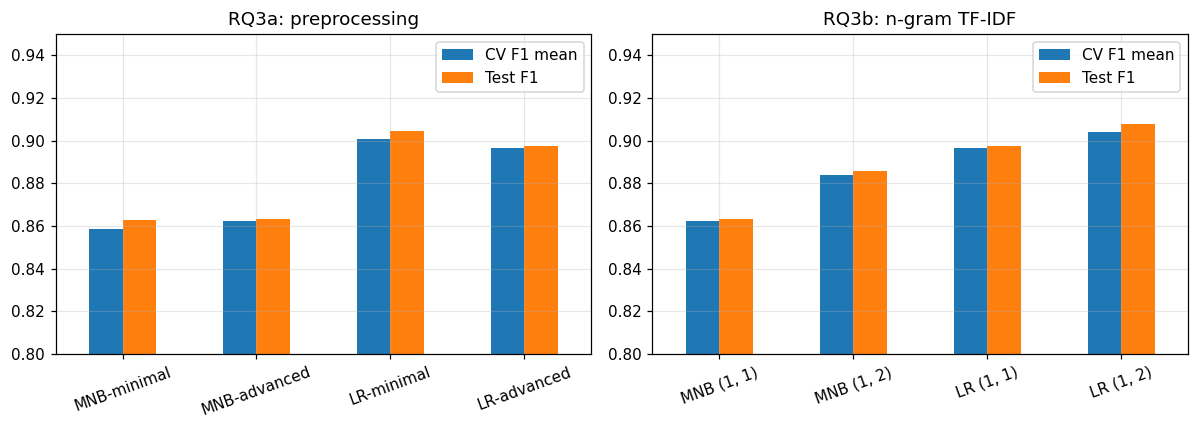

In [ ]:
# ---- (a) Preprocessing: minimal vs lanjutan ----
specs = [
    ("MNB", "minimal",  "text_minimal",  lambda: MultinomialNB(alpha=best_alpha)),
    ("MNB", "advanced", "text_advanced", lambda: MultinomialNB(alpha=best_alpha)),
    ("LR",  "minimal",  "text_minimal",  lambda: LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)),
    ("LR",  "advanced", "text_advanced", lambda: LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)),
]
rows, rq3_fold = [], {}
for mdl, prep, col, mk in specs:
    cvr = cross_validate(make_pipe(mk()), train[col], y_train, cv=cv5, scoring=["accuracy", "f1"], n_jobs=-1)
    rq3_fold[(mdl, prep)] = cvr["test_f1"]
    fitted = make_pipe(mk()).fit(train[col], y_train)
    pt, pp = fitted.predict(test[col]), fitted.predict_proba(test[col])[:, 1]
    rows.append({"Model": mdl, "Preprocessing": prep,
                 "CV F1 mean": cvr["test_f1"].mean(), "CV F1 std": cvr["test_f1"].std(ddof=1),
                 "CV Acc mean": cvr["test_accuracy"].mean(),
                 "Test Acc": accuracy_score(y_test, pt), "Test F1": f1_score(y_test, pt), "Test ROC-AUC": roc_auc_score(y_test, pp)})
rq3_prep = pd.DataFrame(rows)
display(rq3_prep.round(4))

delta_rows = []
for mdl in ["MNB", "LR"]:
    d = rq3_fold[(mdl, "advanced")] - rq3_fold[(mdl, "minimal")]
    tr = rq3_prep[rq3_prep.Model == mdl].set_index("Preprocessing")
    delta_rows.append({"Model": mdl, "Δ CV F1 (adv − min)": d.mean(), "Std Δ antar-fold": d.std(ddof=1),
                       "Fold advanced lebih baik": f"{int((d > 0).sum())}/{len(d)}",
                       "Δ Test F1 (adv − min)": tr.loc["advanced", "Test F1"] - tr.loc["minimal", "Test F1"]})
rq3_delta = pd.DataFrame(delta_rows)
display(rq3_delta.round(4))
print("Tafsir: Δ < 0 berarti preprocessing lanjutan TIDAK membantu. Jika konsisten di CV dan test, laporkan apa adanya.")

# ---- (b) Konfigurasi TF-IDF: unigram vs unigram+bigram (teks utama) ----
rows = []
for mdl, mk in [("MNB", lambda: MultinomialNB(alpha=best_alpha)),
                ("LR", lambda: LogisticRegression(C=best_C, max_iter=1000, random_state=SEED))]:
    for ng in [(1, 1), (1, 2)]:
        cvr = cross_validate(make_pipe(mk(), ng), X_train, y_train, cv=cv5, scoring=["accuracy", "f1"], n_jobs=-1)
        fitted = make_pipe(mk(), ng).fit(X_train, y_train)
        pt = fitted.predict(X_test)
        rows.append({"Model": mdl, "ngram_range": str(ng), "CV F1 mean": cvr["test_f1"].mean(),
                     "CV F1 std": cvr["test_f1"].std(ddof=1), "Test Acc": accuracy_score(y_test, pt), "Test F1": f1_score(y_test, pt)})
rq3_ngram = pd.DataFrame(rows)
display(rq3_ngram.round(4))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
rq3_prep.assign(lbl=rq3_prep.Model + "-" + rq3_prep.Preprocessing).set_index("lbl")[["CV F1 mean", "Test F1"]].plot(kind="bar", ax=ax[0], ylim=(0.8, 0.95), rot=20)
ax[0].set_title("RQ3a: preprocessing"); ax[0].set_xlabel("")
rq3_ngram.assign(lbl=rq3_ngram.Model + " " + rq3_ngram.ngram_range).set_index("lbl")[["CV F1 mean", "Test F1"]].plot(kind="bar", ax=ax[1], ylim=(0.8, 0.95), rot=20)
ax[1].set_title("RQ3b: n-gram TF-IDF"); ax[1].set_xlabel("")
savefig("RQ3_preprocessing_ngram.png")

## 12. RQ4 — Sensitivitas hyperparameter dan stabilitas

> **RQ4.** Seberapa sensitif performa MNB (α) dan LR (C) terhadap hyperparameter, dan seberapa stabil kedua model pada pembagian data yang berbeda (Repeated Stratified K-Fold)?

(a) Sensitivitas dibaca dari hasil grid search; (b) stabilitas dari `RepeatedStratifiedKFold` (5 fold × `RQ4_REPEATS`) pada data latih, dengan mean ± std, CI 95% (t-distribution), serta uji berpasangan **Nadeau–Bengio corrected resampled t-test** (mengoreksi ketergantungan antar-fold) dan Wilcoxon.

,Model,Hyperparameter,Mean CV F1,Std CV F1,Mean Train F1,Rank,Gap train-CV
0,Multinomial Naive Bayes,alpha=0.1,0.8582,0.0039,0.9329,4,0.0748
1,Multinomial Naive Bayes,alpha=0.5,0.8617,0.0040,0.9162,2,0.0544
2,Multinomial Naive Bayes,alpha=1.0,0.8623,0.0035,0.9078,1,0.0455
3,Multinomial Naive Bayes,alpha=2.0,0.8611,0.0048,0.8984,3,0.0373
4,Logistic Regression,C=0.25,0.8847,0.0037,0.9055,5,0.0209
5,Logistic Regression,C=0.5,0.8902,0.0025,0.9198,4,0.0296
6,Logistic Regression,C=1.0,0.8944,0.0022,0.9341,3,0.0397
7,Logistic Regression,C=2.0,0.8968,0.0025,0.9508,1,0.0541
8,Logistic Regression,C=4.0,0.8965,0.0028,0.9666,2,0.0701


MNB: rentang CV F1 di seluruh grid = 0.0041 | selisih peringkat-1 vs 2 = 0.0005 (std CV peringkat-1 = 0.0035)  -> peringkat 1 vs 2 tidak jelas berbeda
LR: rentang CV F1 di seluruh grid = 0.0121 | selisih peringkat-1 vs 2 = 0.0002 (std CV peringkat-1 = 0.0025)  -> peringkat 1 vs 2 tidak jelas berbeda


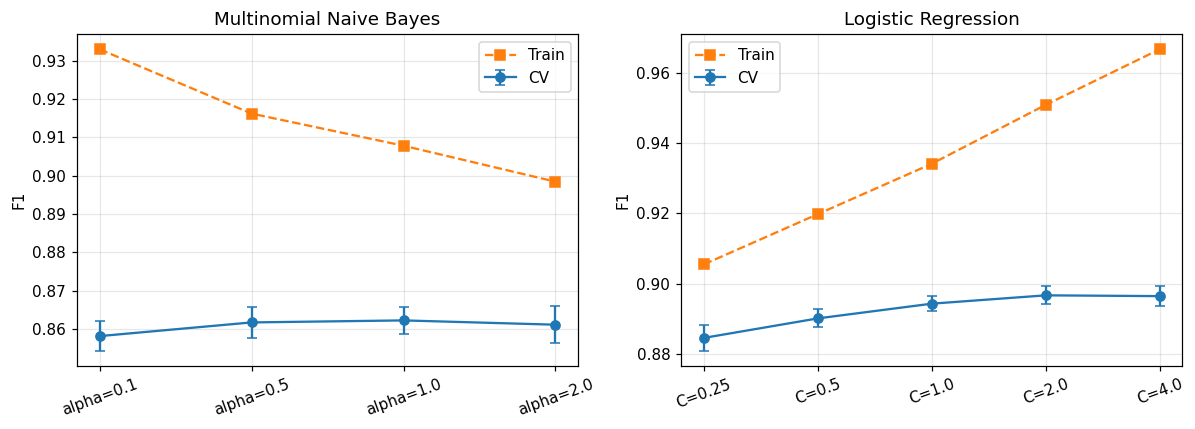

,0,1
Model,Multinomial Naive Bayes,Logistic Regression
accuracy mean,0.8633,0.8949
accuracy std,0.0037,0.0029
accuracy CI95,"[0.8612, 0.8653]","[0.8933, 0.8965]"
precision mean,0.8763,0.8877
precision std,0.0039,0.0038
precision CI95,"[0.8742, 0.8785]","[0.8856, 0.8898]"
recall mean,0.8472,0.905
recall std,0.0069,0.0051
recall CI95,"[0.8434, 0.8510]","[0.9022, 0.9078]"


,Uji,Statistik,p-value,Mean Δ F1 (LR−MNB)
0,Nadeau–Bengio corrected t (two-sided),15.228978,0.000000,0.03477
1,Wilcoxon signed-rank (LR > MNB),120.000000,0.000031,0.03477


LR lebih tinggi pada 15/15 split.
Catatan: p-value minimum Wilcoxon one-sided = 3.1e-05; skor antar-fold tidak independen, jadi utamakan uji Nadeau–Bengio.


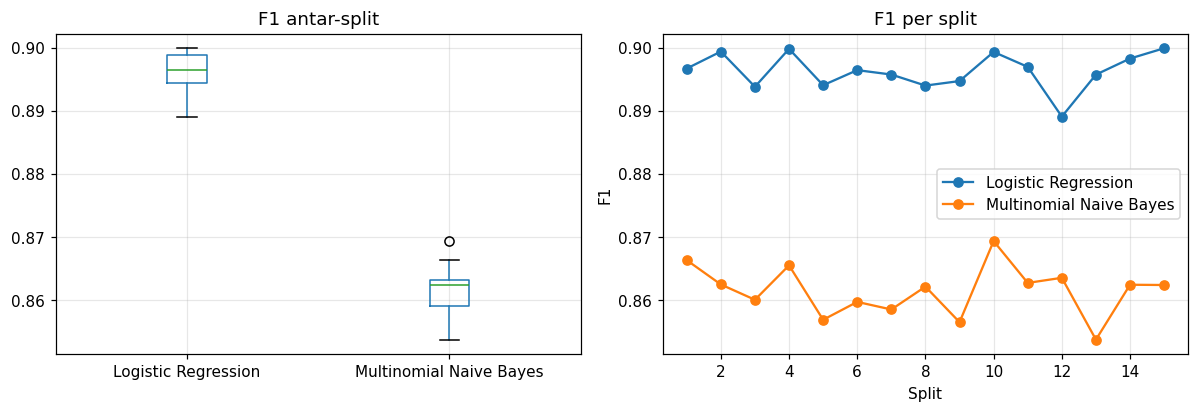

In [ ]:
# ---------- (a) Sensitivitas hyperparameter ----------
def grid_table(g, name, p):
    r = pd.DataFrame(g.cv_results_)
    return pd.DataFrame({
        "Model": name, "Hyperparameter": f"{p}=" + r[f"param_model__{p}"].astype(str),
        "Mean CV F1": r["mean_test_score"], "Std CV F1": r["std_test_score"],
        "Mean Train F1": r["mean_train_score"], "Rank": r["rank_test_score"],
    })

rq4_hyper = pd.concat([grid_table(grid_mnb, "Multinomial Naive Bayes", "alpha"),
                       grid_table(grid_lr, "Logistic Regression", "C")], ignore_index=True)
rq4_hyper["Gap train-CV"] = rq4_hyper["Mean Train F1"] - rq4_hyper["Mean CV F1"]
display(rq4_hyper.round(4))

for g, nm in [(grid_mnb, "MNB"), (grid_lr, "LR")]:
    r = pd.DataFrame(g.cv_results_).sort_values("rank_test_score")
    gap = r["mean_test_score"].iloc[0] - r["mean_test_score"].iloc[1]
    rng_f1 = r["mean_test_score"].max() - r["mean_test_score"].min()
    print(f"{nm}: rentang CV F1 di seluruh grid = {rng_f1:.4f} | selisih peringkat-1 vs 2 = {gap:.4f} "
          f"(std CV peringkat-1 = {r['std_test_score'].iloc[0]:.4f})"
          + ("  -> peringkat 1 vs 2 tidak jelas berbeda" if gap < r["std_test_score"].iloc[0] else ""))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
for a, (nm, grp) in zip(ax, rq4_hyper.groupby("Model", sort=False)):
    a.errorbar(grp["Hyperparameter"], grp["Mean CV F1"], yerr=grp["Std CV F1"], marker="o", capsize=3, label="CV")
    a.plot(grp["Hyperparameter"], grp["Mean Train F1"], marker="s", ls="--", label="Train")
    a.set_title(nm); a.set_ylabel("F1"); a.legend(); a.tick_params(axis="x", rotation=20)
savefig("RQ4_sensitivitas_hyperparameter.png")

# ---------- (b) Stabilitas: Repeated Stratified K-Fold ----------
rcv = RepeatedStratifiedKFold(n_splits=CV_SPLITS, n_repeats=RQ4_REPEATS, random_state=SEED)
scoring = {"accuracy": "accuracy", "precision": "precision", "recall": "recall", "f1": "f1", "roc_auc": "roc_auc"}
cv_models = {"Multinomial Naive Bayes": lambda: make_pipe(MultinomialNB(alpha=best_alpha)),
             "Logistic Regression": lambda: make_pipe(LogisticRegression(C=best_C, max_iter=1000, random_state=SEED))}

folds, summ = [], []
for nm, mk in cv_models.items():
    r = cross_validate(mk(), X_train, y_train, cv=rcv, scoring=scoring, n_jobs=-1)
    row = {"Model": nm}
    for m in scoring:
        v = r[f"test_{m}"]; k = len(v)
        half = t_dist.ppf(0.975, k - 1) * v.std(ddof=1) / np.sqrt(k)
        row[f"{m} mean"] = v.mean(); row[f"{m} std"] = v.std(ddof=1)
        row[f"{m} CI95"] = f"[{v.mean() - half:.4f}, {v.mean() + half:.4f}]"
    summ.append(row)
    for i in range(len(r["test_f1"])):
        folds.append({"Model": nm, "Split": i + 1, **{m: r[f"test_{m}"][i] for m in scoring}})
rq4_stab_summary, rq4_stab_splits = pd.DataFrame(summ), pd.DataFrame(folds)
display(rq4_stab_summary.round(4).T)

a = rq4_stab_splits[rq4_stab_splits.Model == "Logistic Regression"].sort_values("Split")["f1"].to_numpy()
m_ = rq4_stab_splits[rq4_stab_splits.Model == "Multinomial Naive Bayes"].sort_values("Split")["f1"].to_numpy()
d = a - m_; k = len(d)
n_tr_fold = len(y_train) * (CV_SPLITS - 1) / CV_SPLITS; n_te_fold = len(y_train) / CV_SPLITS
t_stat = d.mean() / np.sqrt((1 / k + n_te_fold / n_tr_fold) * d.var(ddof=1))
p_nb = 2 * t_dist.sf(abs(t_stat), k - 1)
w = wilcoxon(a, m_, alternative="greater")
rq4_tests = pd.DataFrame([
    {"Uji": "Nadeau–Bengio corrected t (two-sided)", "Statistik": t_stat, "p-value": p_nb, "Mean Δ F1 (LR−MNB)": d.mean()},
    {"Uji": "Wilcoxon signed-rank (LR > MNB)", "Statistik": w.statistic, "p-value": w.pvalue, "Mean Δ F1 (LR−MNB)": d.mean()},
])
display(rq4_tests.round(6))
print(f"LR lebih tinggi pada {(d > 0).sum()}/{k} split.")
print("Catatan: p-value minimum Wilcoxon one-sided = %.1e; skor antar-fold tidak independen, jadi utamakan uji Nadeau–Bengio." % (0.5 ** k))

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
rq4_stab_splits.boxplot(column="f1", by="Model", ax=ax[0]); ax[0].set_title("F1 antar-split"); ax[0].set_xlabel(""); plt.sca(ax[0]); plt.suptitle("")
for nm, g in rq4_stab_splits.groupby("Model"): ax[1].plot(g["Split"], g["f1"], marker="o", label=nm)
ax[1].set(title="F1 per split", xlabel="Split", ylabel="F1"); ax[1].legend()
savefig("RQ4_stabilitas.png")

## 13. RQ5 — Trade-off akurasi dan efisiensi

> **RQ5.** Bagaimana trade-off antara kualitas prediksi dan biaya komputasi (waktu training, waktu prediksi, throughput) antara MNB dan LR, dan apakah selisih akurasi sebanding dengan selisih waktunya?

Waktu diukur berulang (median + IQR) dan **dipisah** antara TF-IDF dan model. Throughput dilaporkan *end-to-end* (teks → prediksi) dan *model-only* (matriks TF-IDF → prediksi; sebanding dengan angka jurnal acuan).

,0,1
Model,Multinomial Naive Bayes,Logistic Regression
TF-IDF fit (s),5.116,5.4767
TF-IDF fit (s) IQR,0.8575,0.7251
Model fit (s),0.03,1.4617
Model fit (s) IQR,0.0014,0.5812
Train total (s),5.145,6.9276
Train total (s) IQR,0.8382,0.3551
TF-IDF transform test (s),1.9465,2.0581
TF-IDF transform test (s) IQR,0.0385,0.5543
Model predict (s),0.0108,0.0046


,0
Δ F1 (LR−MNB),0.03456
Δ Accuracy (LR−MNB),0.03146
Δ waktu train (s),1.78258
Rasio waktu train LR/MNB,1.34647
Rasio waktu prediksi e2e LR/MNB,1.05345
Rasio waktu prediksi model-only LR/MNB,0.42199
Δ F1 per detik training tambahan,0.01939


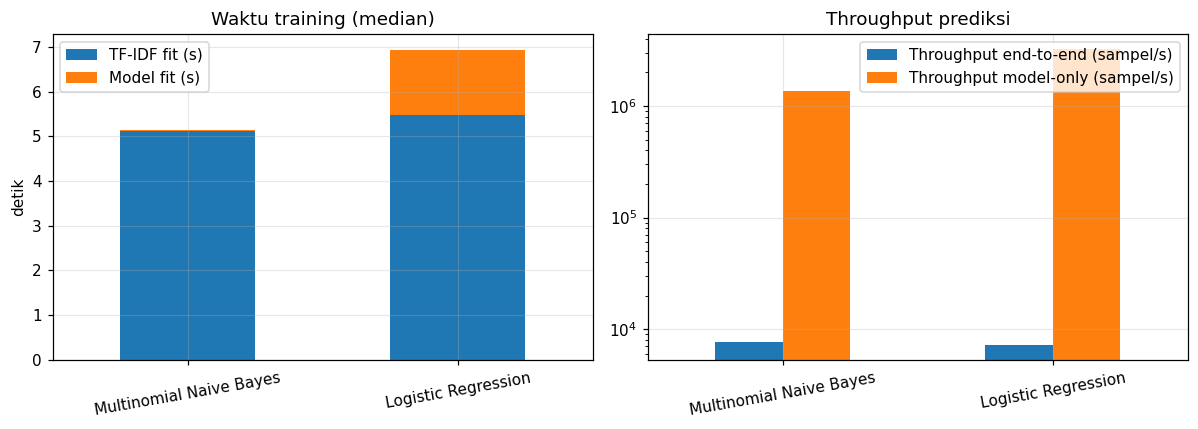

Median dari 5 pengulangan (setelah 1 warm-up). Waktu bergantung pada hardware Colab.


In [ ]:
def time_model(name, make_model, repeats=TIMING_REPEATS):
    rec = []
    for r in range(repeats + 1):                       # run ke-0 = warm-up, dibuang
        vec = TfidfVectorizer(lowercase=False, token_pattern=TOKEN_PATTERN, max_features=MAX_FEATURES, sublinear_tf=True)
        mdl = make_model()
        t0 = time.perf_counter(); Xtr = vec.fit_transform(X_train); t1 = time.perf_counter()
        mdl.fit(Xtr, y_train);                                        t2 = time.perf_counter()
        Xte = vec.transform(X_test);                                  t3 = time.perf_counter()
        mdl.predict(Xte);                                             t4 = time.perf_counter()
        if r > 0:
            rec.append({"vec_fit": t1 - t0, "model_fit": t2 - t1, "vec_transform": t3 - t2, "model_predict": t4 - t3})
    r = pd.DataFrame(rec); n_te = len(X_test)
    r["train_total"] = r.vec_fit + r.model_fit
    r["throughput_e2e"] = n_te / (r.vec_transform + r.model_predict)
    r["throughput_model"] = n_te / r.model_predict
    med, q1, q3 = r.median(), r.quantile(0.25), r.quantile(0.75)
    out = {"Model": name}
    for k, lab in [("vec_fit", "TF-IDF fit (s)"), ("model_fit", "Model fit (s)"), ("train_total", "Train total (s)"),
                   ("vec_transform", "TF-IDF transform test (s)"), ("model_predict", "Model predict (s)")]:
        out[lab] = med[k]; out[lab + " IQR"] = q3[k] - q1[k]
    out["Throughput end-to-end (sampel/s)"] = med["throughput_e2e"]
    out["Throughput model-only (sampel/s)"] = med["throughput_model"]
    return out

rq5_df = pd.DataFrame([
    time_model("Multinomial Naive Bayes", lambda: MultinomialNB(alpha=best_alpha)),
    time_model("Logistic Regression", lambda: LogisticRegression(C=best_C, max_iter=1000, random_state=SEED)),
])
display(rq5_df.round(4).T)

# ---- trade-off: kualitas vs biaya ----
t_m, t_l = rq5_df.iloc[0], rq5_df.iloc[1]
q_m = rq1_df[rq1_df.Model == NM_MNB].iloc[0]; q_l = rq1_df[rq1_df.Model == NM_LR].iloc[0]
d_f1, d_acc = q_l["F1-score"] - q_m["F1-score"], q_l["Accuracy"] - q_m["Accuracy"]
d_sec = t_l["Train total (s)"] - t_m["Train total (s)"]
rq5_tradeoff = pd.DataFrame([{
    "Δ F1 (LR−MNB)": d_f1, "Δ Accuracy (LR−MNB)": d_acc,
    "Δ waktu train (s)": d_sec, "Rasio waktu train LR/MNB": t_l["Train total (s)"] / t_m["Train total (s)"],
    "Rasio waktu prediksi e2e LR/MNB": t_m["Throughput end-to-end (sampel/s)"] / t_l["Throughput end-to-end (sampel/s)"],
    "Rasio waktu prediksi model-only LR/MNB": t_m["Throughput model-only (sampel/s)"] / t_l["Throughput model-only (sampel/s)"],
    "Δ F1 per detik training tambahan": d_f1 / d_sec if d_sec > 0 else np.nan,
}])
display(rq5_tradeoff.round(5).T)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
rq5_df.set_index("Model")[["TF-IDF fit (s)", "Model fit (s)"]].plot(kind="bar", stacked=True, ax=ax[0], rot=10)
ax[0].set_title("Waktu training (median)"); ax[0].set_ylabel("detik"); ax[0].set_xlabel("")
rq5_df.set_index("Model")[["Throughput end-to-end (sampel/s)", "Throughput model-only (sampel/s)"]].plot(kind="bar", ax=ax[1], logy=True, rot=10)
ax[1].set_title("Throughput prediksi"); ax[1].set_xlabel("")
savefig("RQ5_efisiensi.png")
print(f"Median dari {TIMING_REPEATS} pengulangan (setelah 1 warm-up). Waktu bergantung pada hardware Colab.")

## 14. Ringkasan otomatis & ekspor ZIP

In [ ]:
r_m = rq1_df[rq1_df.Model == NM_MNB].iloc[0]; r_l = rq1_df[rq1_df.Model == NM_LR].iloc[0]
s_f1 = rq1_stats[rq1_stats.Uji.str.contains("Δ F1")].iloc[0]
winner = "Logistic Regression" if r_l["F1-score"] > r_m["F1-score"] else "Multinomial Naive Bayes"
sig = (s_f1["CI95 bawah"] > 0) or (s_f1["CI95 atas"] < 0)

print("=" * 80); print("RINGKASAN OTOMATIS (per RQ)"); print("=" * 80)
print(f"Data : {len(data):,} review unik (duplikat dibuang: {n_dup}); train {len(train):,} / test {len(test):,}")
print(f"Model: MNB alpha*={best_alpha} | LR C*={best_C} (dipilih lewat CV pada data latih)\n")

print(f"RQ1  Performa      : F1 MNB={r_m['F1-score']:.4f} vs LR={r_l['F1-score']:.4f} -> unggul: {winner}")
print(f"                     Acc MNB={r_m['Accuracy']:.4f} vs LR={r_l['Accuracy']:.4f} | ROC-AUC MNB={r_m['ROC-AUC']:.4f} vs LR={r_l['ROC-AUC']:.4f}")
print(f"                     Δ F1 (LR−MNB)={s_f1['Estimasi']:.4f}, CI95 [{s_f1['CI95 bawah']:.4f}, {s_f1['CI95 atas']:.4f}] -> {'berbeda' if sig else 'tidak jelas berbeda'}; McNemar p={mcnemar_p:.2e}")

print(f"RQ2  Pola kesalahan: FP MNB={r_m['FP']} LR={r_l['FP']} | FN MNB={r_m['FN']} LR={r_l['FN']}")
worst = rq2_panjang.loc[rq2_panjang["Error LR"].idxmax(), "len_bin"]
print(f"                     error LR tertinggi pada kuartil panjang: {worst} | error negasi LR per bin: " +
      ", ".join(f"{r.neg_bin}={r['Error LR']:.3f}" for _, r in rq2_negasi.iterrows()))

for _, r in rq3_delta.iterrows():
    print(f"RQ3  Preprocessing : {r['Model']}: Δ CV F1 (adv−min)={r['Δ CV F1 (adv − min)']:+.4f}, Δ Test F1={r['Δ Test F1 (adv − min)']:+.4f}")
for mdl in ["MNB", "LR"]:
    g = rq3_ngram[rq3_ngram.Model == mdl].set_index("ngram_range")
    print(f"RQ3  n-gram        : {mdl}: CV F1 (1,1)={g.loc['(1, 1)', 'CV F1 mean']:.4f} -> (1,2)={g.loc['(1, 2)', 'CV F1 mean']:.4f}")

for nm, tag in [("Multinomial Naive Bayes", "MNB"), ("Logistic Regression", "LR")]:
    gsub = rq4_hyper[rq4_hyper.Model == nm]
    print(f"RQ4  Sensitivitas  : {tag}: rentang CV F1 antar-hyperparameter = {gsub['Mean CV F1'].max() - gsub['Mean CV F1'].min():.4f}")
print(f"RQ4  Stabilitas    : std F1 MNB={rq4_stab_summary.iloc[0]['f1 std']:.4f}, LR={rq4_stab_summary.iloc[1]['f1 std']:.4f}; Nadeau–Bengio p={p_nb:.3g}")

print(f"RQ5  Efisiensi     : train total (median) MNB={t_m['Train total (s)']:.2f}s vs LR={t_l['Train total (s)']:.2f}s "
      f"(rasio {t_l['Train total (s)'] / t_m['Train total (s)']:.2f}×); Δ F1={d_f1:+.4f}")
print(f"                     throughput model-only MNB={t_m['Throughput model-only (sampel/s)']:.0f} vs LR={t_l['Throughput model-only (sampel/s)']:.0f} sampel/s")
print("\nSanity: label-shuffle ≈ 0.5 (tidak ada indikasi leakage)")

protocol = pd.DataFrame([
    {"Setting": "Seed", "Value": SEED},
    {"Setting": "Split", "Value": f"{int((1 - TEST_SIZE) * 100)}:{int(TEST_SIZE * 100)} stratified"},
    {"Setting": "Deduplikasi", "Value": f"exact, sebelum split ({n_dup} dibuang)"},
    {"Setting": "TF-IDF", "Value": f"max_features={MAX_FEATURES}, ngram=(1,1) utama, (1,2) pada RQ3, sublinear_tf=True, token_pattern={TOKEN_PATTERN}"},
    {"Setting": "Teks utama", "Value": MAIN_TEXT},
    {"Setting": "Negasi dipertahankan", "Value": f"{len(NEGATIONS)} kata (termasuk bentuk n't)"},
    {"Setting": "Tuning", "Value": f"GridSearchCV {CV_SPLITS}-fold, scoring=F1, hanya data latih"},
    {"Setting": "RQ4 stabilitas", "Value": f"RepeatedStratifiedKFold {CV_SPLITS}x{RQ4_REPEATS}"},
    {"Setting": "Bootstrap (RQ1)", "Value": f"{N_BOOT} resampel, seed={SEED + 100}"},
    {"Setting": "Pengulangan timing (RQ5)", "Value": TIMING_REPEATS},
    {"Setting": "Python / sklearn / pandas / numpy / scipy / nltk",
     "Value": f"{platform.python_version()} / {sklearn.__version__} / {pd.__version__} / {np.__version__} / {scipy.__version__} / {nltk.__version__}"},
    {"Setting": "Perbedaan dari jurnal acuan", "Value": "Hold-out 70:30 + CV di data latih (acuan: nested 5-fold CV); unigram utama & 50.000 fitur (acuan: uni+bigram, 10.000 fitur); deduplikasi (acuan: tidak)."},
    {"Setting": "Timestamp UTC", "Value": datetime.datetime.now(datetime.timezone.utc).isoformat()},
])
display(protocol)

tables = {
    "00_validasi_dataset.csv": validation_report, "00_distribusi_split.csv": split_report,
    "00_sanity_check.csv": sanity, "00_protokol_eksperimen.csv": protocol,
    "RQ1_performa_model.csv": rq1_df, "RQ1_uji_statistik.csv": rq1_stats,
    "RQ2_komposisi_error.csv": rq2_komposisi, "RQ2_error_panjang.csv": rq2_panjang, "RQ2_error_negasi.csv": rq2_negasi,
    "RQ2_fitur_LR.csv": rq2_fitur_lr, "RQ2_fitur_MNB.csv": rq2_fitur_mnb, "RQ2_contoh_error_LR.csv": rq2_contoh,
    "RQ3_preprocessing.csv": rq3_prep, "RQ3_delta_preprocessing.csv": rq3_delta, "RQ3_ngram_tfidf.csv": rq3_ngram,
    "RQ4_sensitivitas_hyperparameter.csv": rq4_hyper, "RQ4_stabilitas_ringkasan.csv": rq4_stab_summary,
    "RQ4_stabilitas_per_split.csv": rq4_stab_splits, "RQ4_uji_berpasangan.csv": rq4_tests,
    "RQ5_efisiensi.csv": rq5_df, "RQ5_tradeoff.csv": rq5_tradeoff,
}
for fn, tb in tables.items(): tb.to_csv(fn, index=False)

zip_name = "hasil_validasi_IMDb_RQ1-RQ5.zip"
with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    for fn in tables: z.write(fn)
    for fn in dict.fromkeys(FIG_FILES):
        if os.path.exists(fn): z.write(fn)
print("\nSelesai ->", zip_name, "| isi:", len(tables), "tabel CSV +", len(set(FIG_FILES)), "gambar")
if IN_COLAB: files.download(zip_name)

RINGKASAN OTOMATIS (per RQ)
Data : 49,582 review unik (duplikat dibuang: 418); train 34,707 / test 14,875
Model: MNB alpha*=1.0 | LR C*=2 (dipilih lewat CV pada data latih)

RQ1  Performa      : F1 MNB=0.8630 vs LR=0.8976 -> unggul: Logistic Regression
                     Acc MNB=0.8643 vs LR=0.8958 | ROC-AUC MNB=0.9374 vs LR=0.9617
                     Δ F1 (LR−MNB)=0.0346, CI95 [0.0294, 0.0397] -> berbeda; McNemar p=8.24e-33
RQ2  Pola kesalahan: FP MNB=911 LR=878 | FN MNB=1107 LR=672
                     error LR tertinggi pada kuartil panjang: Q3 | error negasi LR per bin: 0=0.099, 1–2=0.103, 3–5=0.107, >5=0.106
RQ3  Preprocessing : MNB: Δ CV F1 (adv−min)=+0.0035, Δ Test F1=+0.0003
RQ3  Preprocessing : LR: Δ CV F1 (adv−min)=-0.0039, Δ Test F1=-0.0068
RQ3  n-gram        : MNB: CV F1 (1,1)=0.8623 -> (1,2)=0.8837
RQ3  n-gram        : LR: CV F1 (1,1)=0.8968 -> (1,2)=0.9043
RQ4  Sensitivitas  : MNB: rentang CV F1 antar-hyperparameter = 0.0041
RQ4  Sensitivitas  : LR: rentang CV F1 antar

,Setting,Value
0,Seed,42
1,Split,70:30 stratified
2,Deduplikasi,"exact, sebelum split (418 dibuang)"
3,TF-IDF,"max_features=50000, ngram=(1,1) utama, (1,2) pada RQ3, sublinear_tf=True, token_pattern=(?u)\b\w[\w']*\b"
4,Teks utama,text_advanced
5,Negasi dipertahankan,21 kata (termasuk bentuk n't)
6,Tuning,"GridSearchCV 5-fold, scoring=F1, hanya data latih"
7,RQ4 stabilitas,RepeatedStratifiedKFold 5x3
8,Bootstrap (RQ1),"2000 resampel, seed=142"
9,Pengulangan timing (RQ5),5



Selesai -> hasil_validasi_IMDb_RQ1-RQ5.zip | isi: 21 tabel CSV + 8 gambar


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>